# Lecture 03 - Spoofed Audio Detection (ASVspoof 2019 LA)

Binary classification of speech as **bonafide** (real) or **spoof** (synthetic) on a balanced subset of the ASVspoof 2019 *logical access* (LA) dataset. Audio features come from pyAudioAnalysis, and an SVM is trained on the train partition and tested on the evaluation partition, whose speakers and attacks are never seen in training.

**Execution.** The pipeline needs no GPU and processes 400 short files, so this notebook was executed locally on a CPU. Colab was not needed.

## Dataset

ASVspoof 2019 [1, 2] has two scenarios: *logical access* (speech produced by text-to-speech and voice conversion) and *physical access* (replayed recordings). Only LA is used here, since the two scenarios involve different artefacts and are usually handled by separate detectors.

| Partition | Bonafide | Spoof | Attacks | Speakers |
|---|---|---|---|---|
| train | 2,580 | 22,800 | A01-A06 | 20 |
| eval | 7,355 | 63,882 | A07-A19 | 67 |

The full dataset is 25 GB on Kaggle ([awsaf49/asvpoof-2019-dataset](https://www.kaggle.com/datasets/awsaf49/asvpoof-2019-dataset)). The audio is read instead from the Hugging Face mirror [Bisher/ASVspoof_2019_LA](https://huggingface.co/datasets/Bisher/ASVspoof_2019_LA), a Parquet copy of the same FLAC files stored in groups of 100 rows, so only the groups containing the sampled files are downloaded (about 1.6 GB, once). The official CM protocols (labels and attack IDs) come from [Nemez1z/asvspoof-2019-la](https://huggingface.co/datasets/Nemez1z/asvspoof-2019-la). Both repositories are pinned to a commit. The data is distributed under the ODC-By license.

**Subset.** 100 bonafide and 100 spoof files are drawn at random (fixed seed) from each partition: 400 files, 16 kHz mono FLAC. Spoof files are sampled uniformly, so the six training attacks and the thirteen evaluation attacks all appear.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem

AUDIO_REPOSITORY = "datasets/Bisher/ASVspoof_2019_LA@aea92dd83a9c56e070c0b1e9f02e7c0d96216a4c"
PROTOCOLS_URL = (
    "https://huggingface.co/datasets/Nemez1z/asvspoof-2019-la/resolve/"
    "4ad1b061fa6dc502b30888ee467ed4115fdb44eb/ASVspoof2019_LA_cm_protocols"
)
PARQUET_FILES = {"train": "train-00000-of-00001.parquet", "eval": "test-00000-of-00001.parquet"}
PROTOCOL_FILES = {"train": "ASVspoof2019.LA.cm.train.trn.txt", "eval": "ASVspoof2019.LA.cm.eval.trl.txt"}
SAMPLES_PER_LABEL = 100
SEED = 0

DATA_DIR = Path("data/asvspoof2019_la_subset")


def load_protocol(split: str) -> pd.DataFrame:
    """Reads the official CM protocol of a partition, one row per utterance in dataset order."""
    columns = ["speaker_id", "utterance_id", "unused", "attack_id", "label"]
    protocol = pd.read_csv(f"{PROTOCOLS_URL}/{PROTOCOL_FILES[split]}", sep=" ", names=columns)
    return protocol.drop(columns="unused").assign(split=split)


def build_subset(split: str) -> pd.DataFrame:
    """Samples a balanced subset of a partition and saves its FLAC files under DATA_DIR/<split>."""
    metadata_path = DATA_DIR / f"{split}.csv"
    if metadata_path.exists():
        return pd.read_csv(metadata_path)

    subset = load_protocol(split).groupby("label").sample(SAMPLES_PER_LABEL, random_state=SEED)
    split_dir = DATA_DIR / split
    split_dir.mkdir(parents=True, exist_ok=True)
    parquet_path = f"{AUDIO_REPOSITORY}/data/{PARQUET_FILES[split]}"
    file_system = HfFileSystem()
    with file_system.open(parquet_path) as handle:
        rows_per_group = pq.ParquetFile(handle).metadata.row_group(0).num_rows
    wanted = set(subset.utterance_id)

    def save_row_group(row_group: int) -> None:
        with file_system.open(parquet_path) as handle:
            table = pq.ParquetFile(handle).read_row_group(row_group, columns=["audio_file_name", "audio"])
        for name, audio in zip(table["audio_file_name"].to_pylist(), table["audio"].to_pylist()):
            if name in wanted:
                (split_dir / f"{name}.flac").write_bytes(audio["bytes"])

    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(save_row_group, sorted(set(subset.index // rows_per_group))))

    missing = [name for name in wanted if not (split_dir / f"{name}.flac").exists()]
    if missing:
        raise RuntimeError(f"{len(missing)} sampled files not found in the Parquet row groups")
    subset.to_csv(metadata_path, index=False)
    return subset


subset = pd.concat([build_subset("train"), build_subset("eval")], ignore_index=True)
subset["path"] = [DATA_DIR / split / f"{name}.flac" for split, name in zip(subset.split, subset.utterance_id)]
size_mb = sum(path.stat().st_size for path in subset.path) / 1e6
print(f"{len(subset)} files, {size_mb:.1f} MB in {DATA_DIR}")
pd.crosstab(subset.attack_id, [subset.split, subset.label], margins=True)

400 files, 24.7 MB in data\asvspoof2019_la_subset


split         eval          train        All
label     bonafide spoof bonafide spoof     
attack_id                                   
-              100     0      100     0  200
A01              0     0        0    16   16
A02              0     0        0    16   16
A03              0     0        0    17   17
A04              0     0        0    20   20
A05              0     0        0    18   18
A06              0     0        0    13   13
A07              0     7        0     0    7
A08              0     9        0     0    9
A09              0     5        0     0    5
A10              0     8        0     0    8
A11              0     7        0     0    7
A12              0    13        0     0   13
A13              0     8        0     0    8
A14              0     9        0     0    9
A15              0     8        0     0    8
A16              0     6        0     0    6
A17              0     7        0     0    7
A18              0     8        0     0    8
A19              0     5        0     0    5
All            100   100      100   100  400

## Feature extraction

Each file is split into 50 ms frames with a 25 ms step, and pyAudioAnalysis [3] computes 34 short-term features per frame: zero-crossing rate, energy, energy entropy, five spectral features, 13 MFCCs and 13 chroma values. The mean and standard deviation over the frames give 68 features per file.

Three duration features are added: total duration and leading and trailing silence, measured with `librosa.effects.trim` at 40 dB below the peak. Müller et al. [4] showed that in ASVspoof 2019 LA the bonafide recordings have longer silences than the spoofed ones, so the silence features are kept separately to check how much of the result depends on this shortcut.

In [2]:
import librosa
import numpy as np
import soundfile as sf
from pyAudioAnalysis import ShortTermFeatures

FRAME_SECONDS = 0.050
STEP_SECONDS = 0.025
SILENCE_TOP_DB = 40
SILENCE_FEATURES = ["leading_silence_s", "trailing_silence_s"]
DURATION_FEATURES = ["duration_s", *SILENCE_FEATURES]


def extract_features(path: Path) -> dict[str, float]:
    """Computes the per-file statistics of the pyAudioAnalysis short-term features and the silence durations."""
    signal, sample_rate = sf.read(path)
    frames, names = ShortTermFeatures.feature_extraction(
        signal, sample_rate, int(FRAME_SECONDS * sample_rate), int(STEP_SECONDS * sample_rate), deltas=False
    )
    features = {f"{name}_mean": value for name, value in zip(names, frames.mean(axis=1))}
    features |= {f"{name}_std": value for name, value in zip(names, frames.std(axis=1))}
    _, (speech_start, speech_end) = librosa.effects.trim(signal, top_db=SILENCE_TOP_DB)
    features["duration_s"] = len(signal) / sample_rate
    features["leading_silence_s"] = speech_start / sample_rate
    features["trailing_silence_s"] = (len(signal) - speech_end) / sample_rate
    return features


features = pd.DataFrame([extract_features(path) for path in subset.path])
dataset = pd.concat([subset, features], axis=1)
dataset["is_spoof"] = dataset.label.eq("spoof").astype(int)
FEATURES = list(features.columns)
print(f"{len(FEATURES)} features per file")
dataset[["split", "utterance_id", "attack_id", "label", *FEATURES[:3], "duration_s", *SILENCE_FEATURES]].head()

71 features per file


,split,utterance_id,attack_id,label,zcr_mean,energy_mean,energy_entropy_mean,duration_s,leading_silence_s,trailing_silence_s
0,train,LA_T_4740742,-,bonafide,0.103663,0.011929,2.794458,3.795875,1.120,0.000000
1,train,LA_T_7300523,-,bonafide,0.101620,0.011911,2.987058,4.776187,0.960,0.648188
2,train,LA_T_3325414,-,bonafide,0.096544,0.009558,2.863251,4.730562,1.632,0.506563
3,train,LA_T_5639776,-,bonafide,0.100991,0.007619,2.958423,3.027375,0.928,0.595375
4,train,LA_T_4638884,-,bonafide,0.110930,0.012242,2.916064,3.236375,1.024,0.484375


## Exploratory analysis

The discriminative power of each feature alone is measured by its ROC AUC between bonafide and spoof (0.5 means no separation; values below 0.5 mean the feature is lower for spoof, so the table reports `max(AUC, 1 - AUC)`). The AUC is computed on the train subset and again on the eval subset, to see which features still separate the classes when the attacks are new. The table lists the ten best pyAudioAnalysis features and the three duration features.

In [3]:
from sklearn.metrics import roc_auc_score

train = dataset[dataset.split == "train"]
test = dataset[dataset.split == "eval"]


def separation(split_data: pd.DataFrame, feature: str) -> float:
    auc = roc_auc_score(split_data.is_spoof, split_data[feature])
    return max(auc, 1 - auc)


feature_ranking = pd.DataFrame(
    {
        "bonafide_mean": train[train.label == "bonafide"][FEATURES].mean(),
        "spoof_mean": train[train.label == "spoof"][FEATURES].mean(),
        "auc_train": [separation(train, feature) for feature in FEATURES],
        "auc_eval": [separation(test, feature) for feature in FEATURES],
    },
    index=FEATURES,
).sort_values("auc_train", ascending=False)
pd.concat([feature_ranking.drop(DURATION_FEATURES).head(10), feature_ranking.loc[DURATION_FEATURES]]).round(3)

,bonafide_mean,spoof_mean,auc_train,auc_eval
mfcc_5_mean,-0.018,-0.204,0.755,0.781
spectral_spread_mean,0.225,0.214,0.753,0.846
mfcc_2_std,0.994,1.157,0.749,0.723
chroma_3_mean,0.051,0.039,0.745,0.789
mfcc_11_mean,0.044,-0.029,0.730,0.629
chroma_3_std,0.052,0.043,0.720,0.789
chroma_9_mean,0.005,0.007,0.720,0.640
mfcc_4_mean,0.172,-0.019,0.713,0.774
mfcc_8_mean,0.119,0.020,0.694,0.650
chroma_6_mean,0.008,0.011,0.692,0.630


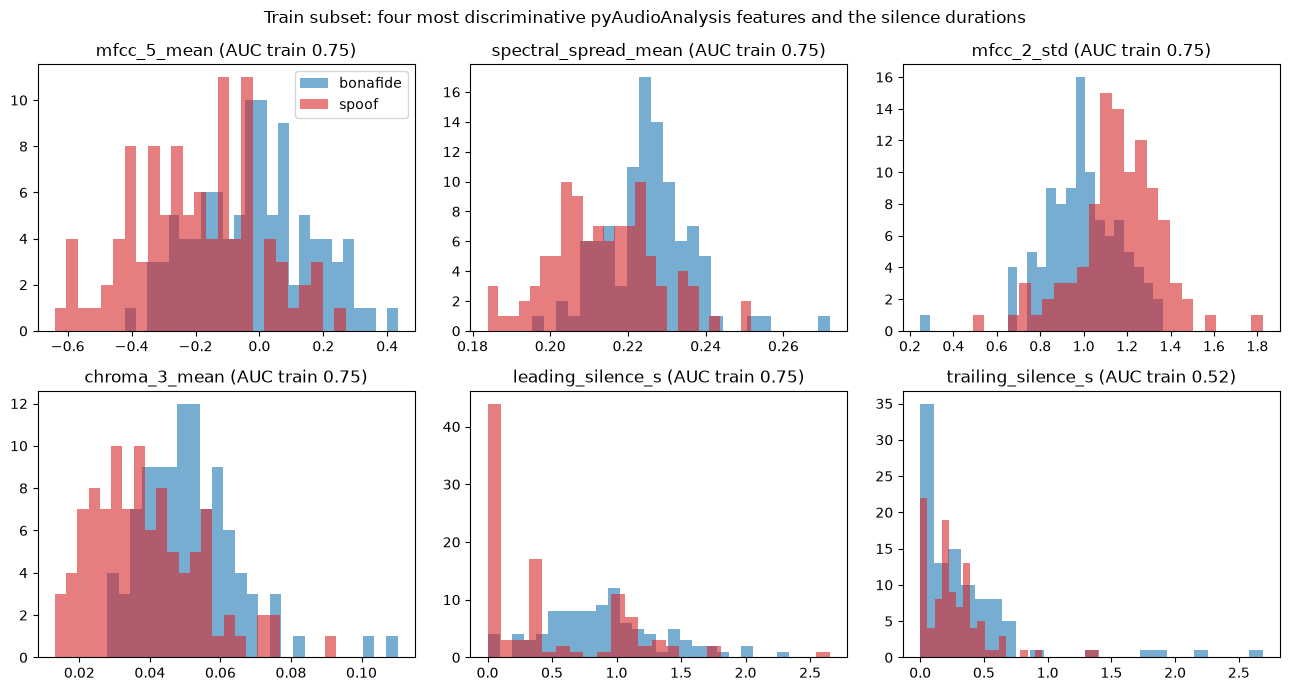

In [4]:
import matplotlib.pyplot as plt

IMAGES_DIR = Path("../../images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

plotted_features = [*feature_ranking.drop(DURATION_FEATURES).index[:4], *SILENCE_FEATURES]
figure, axes = plt.subplots(2, 3, figsize=(13, 7))
for axis, feature in zip(axes.flat, plotted_features):
    for label, color in [("bonafide", "tab:blue"), ("spoof", "tab:red")]:
        axis.hist(train[train.label == label][feature], bins=25, alpha=0.6, color=color, label=label)
    axis.set_title(f"{feature} (AUC train {feature_ranking.auc_train[feature]:.2f})")
axes[0, 0].legend()
figure.suptitle("Train subset: four most discriminative pyAudioAnalysis features and the silence durations")
figure.tight_layout()
figure.savefig(IMAGES_DIR / "aula_03_features.png", dpi=120)
plt.show()

## Classifiers

- **SVM** on all 71 features, following the pipeline of the vocaloid case study by Almeida and Hayashi [5]: standardisation, then an SVM whose kernel and `C` are chosen by `GridSearchCV` maximising ROC AUC. The folds are split by speaker (`StratifiedGroupKFold`), so the validation score is not inflated by the same voice appearing in training and validation folds.
- **Silence baseline**: a logistic regression on the two silence features only. Its result measures how far the silence shortcut alone goes.

Both models are trained on the train subset (attacks A01-A06) and tested on the eval subset (attacks A07-A19, unseen speakers). Besides accuracy, F1 (with spoof as the positive class) and ROC AUC, the table reports the equal error rate (EER), the standard ASVspoof metric: the operating point where the rate of spoofs accepted as bonafide equals the rate of bonafide rejected as spoof.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

speaker_folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


def equal_error_rate(is_spoof: pd.Series, scores: np.ndarray) -> float:
    false_positive_rate, true_positive_rate, _ = roc_curve(is_spoof, scores)
    false_negative_rate = 1 - true_positive_rate
    threshold_index = np.argmin(np.abs(false_negative_rate - false_positive_rate))
    return (false_positive_rate[threshold_index] + false_negative_rate[threshold_index]) / 2


def evaluate(model_name: str, model, columns: list[str]) -> dict:
    cv_auc = cross_val_score(model, train[columns], train.is_spoof, groups=train.speaker_id, cv=speaker_folds, scoring="roc_auc")
    model.fit(train[columns], train.is_spoof)
    scores = model.decision_function(test[columns])
    predictions = model.predict(test[columns])
    return {
        "model": model_name,
        "features": len(columns),
        "cv_auc_train": cv_auc.mean(),
        "accuracy_eval": accuracy_score(test.is_spoof, predictions),
        "f1_eval": f1_score(test.is_spoof, predictions),
        "auc_eval": roc_auc_score(test.is_spoof, scores),
        "eer_eval": equal_error_rate(test.is_spoof, scores),
    }


svm_search = GridSearchCV(
    make_pipeline(StandardScaler(), SVC()),
    {"svc__kernel": ["linear", "rbf"], "svc__C": [0.1, 1, 10, 100]},
    scoring="roc_auc",
    cv=speaker_folds,
)
svm_search.fit(train[FEATURES], train.is_spoof, groups=train.speaker_id)
print(f"SVM grid search: best {svm_search.best_params_}, CV AUC {svm_search.best_score_:.3f}")
svm = svm_search.best_estimator_

silence_baseline = make_pipeline(StandardScaler(), LogisticRegression())
results = pd.DataFrame([
    evaluate("Silence baseline (logistic regression)", silence_baseline, SILENCE_FEATURES),
    evaluate("SVM, all features", svm, FEATURES),
])
results.round(3)

SVM grid search: best {'svc__C': 1, 'svc__kernel': 'rbf'}, CV AUC 0.930


,model,features,cv_auc_train,accuracy_eval,f1_eval,auc_eval,eer_eval
0,Silence baseline (logistic regression),2,0.744,0.720,0.765,0.897,0.165
1,"SVM, all features",71,0.930,0.865,0.862,0.922,0.125


## Results on the eval subset

Per-attack view of the SVM: the share of each attack's files classified as spoof (detection rate) and the share of bonafide files classified as bonafide, next to the mean leading silence of each group. With about 8 files per attack, each rate is a rough indication only.

           files  correct_rate  leading_silence_s
attack_id                                        
-            100          0.89               0.82
A07            7          1.00               0.01
A08            9          1.00               0.20
A09            5          1.00               0.03
A10            8          1.00               0.01
A11            7          1.00               0.00
A12           13          1.00               0.01
A13            8          1.00               0.00
A14            9          1.00               0.00
A15            8          1.00               0.05
A16            6          1.00               0.03
A17            7          0.00               0.87
A18            8          0.38               0.76
A19            5          0.20               0.13


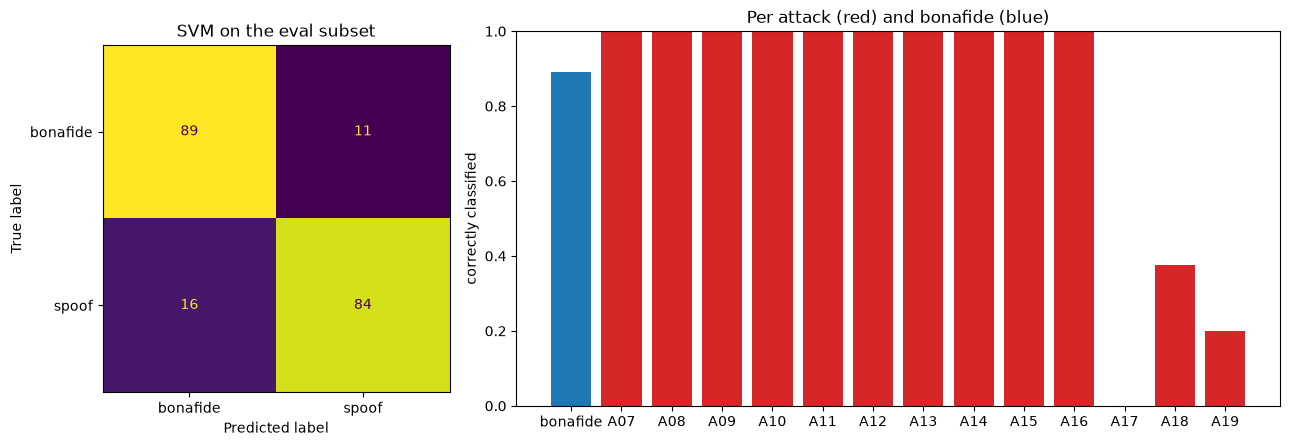

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

test = test.assign(svm_score=svm.decision_function(test[FEATURES]), svm_prediction=svm.predict(test[FEATURES]))
test["correct"] = test.svm_prediction == test.is_spoof
per_attack = test.groupby("attack_id").agg(
    files=("correct", "size"), correct_rate=("correct", "mean"), leading_silence_s=("leading_silence_s", "mean")
)
print(per_attack.round(2).to_string())

figure, (matrix_axis, attack_axis) = plt.subplots(1, 2, figsize=(13, 4.5), width_ratios=[1, 2.2])
ConfusionMatrixDisplay.from_predictions(
    test.is_spoof, test.svm_prediction, display_labels=["bonafide", "spoof"], colorbar=False, ax=matrix_axis
)
matrix_axis.set_title("SVM on the eval subset")
colors = ["tab:blue" if attack == "-" else "tab:red" for attack in per_attack.index]
attack_axis.bar(per_attack.index.str.replace("-", "bonafide"), per_attack.correct_rate, color=colors)
attack_axis.set_ylim(0, 1)
attack_axis.set_ylabel("correctly classified")
attack_axis.set_title("Per attack (red) and bonafide (blue)")
figure.tight_layout()
figure.savefig(IMAGES_DIR / "aula_03_results.png", dpi=120)
plt.show()

## Conclusions

- **Silence alone goes a long way.** Leading silence separates the eval subset better than any feature in the ranking table (AUC 0.91): in the train subset bonafide files start with 0.90 s of silence on average and spoofed files with 0.46 s. The silence baseline reaches an EER of 16.5% on unseen attacks, close to the 15.1% that Müller et al. [4] report for leading silence on the full eval set.
- **The SVM improves on the shortcut but does not remove the doubt.** With all 71 features (RBF kernel, `C=1`) it reaches 86.5% accuracy, F1 0.86, ROC AUC 0.92 and EER 12.5% on unseen speakers and attacks. For reference, the official CQCC-GMM and LFCC-GMM baselines reach 9.57% and 8.09% EER on the full eval set, trained on the full train set of 25,380 files instead of 200 [2]. How much of the SVM decision still relies on silence is not measured here.
- **Errors concentrate on the three pure voice-conversion attacks.** The other eval attacks are text-to-speech, or text-to-speech followed by voice conversion (A13-A15), and all their files are detected. The three attacks that convert a real human recording mostly pass as bonafide [1]:
  - A17, VAE-based conversion with waveform filtering: 0/7 detected.
  - A18, i-vector/PLDA conversion with an MFCC vocoder: 3/8 detected.
  - A19, GMM-UBM transfer-function conversion: 1/5 detected.
- **The silence shortcut explains A17 and A18, but not A19.** A likely reason is that voice conversion starts from a real recording and keeps its silences: the mean leading silence of A17 (0.87 s) and A18 (0.76 s) is close to bonafide (0.82 s), while the text-to-speech attacks have at most 0.20 s. A19 has short silences (0.13 s) and is still missed, even though it uses the same algorithm as A06, which is in the training set [1]. A17 was also one of the hardest attacks for the official baselines [1]. On the bonafide side, 11 of 100 files are rejected.
- **Limitations.** Each partition contributes 200 files, and the per-attack rates come from 5 to 13 files each, so they are indicative only. Natural next steps are removing the silence features (or trimming the audio) to measure the dependence on the shortcut, comparing other classifiers and using larger subsets.

## References

1. X. Wang et al. *ASVspoof 2019: A large-scale public database of synthesized, converted and replayed speech*. Computer Speech & Language, 64, 101114, 2020. DOI: [10.1016/j.csl.2020.101114](https://doi.org/10.1016/j.csl.2020.101114).
2. M. Todisco et al. *ASVspoof 2019: Future horizons in spoofed and fake audio detection*. Interspeech 2019. [arXiv:1904.05441](https://arxiv.org/abs/1904.05441).
3. T. Giannakopoulos. *pyAudioAnalysis: An open-source Python library for audio signal analysis*. PLoS ONE, 10(12), e0144610, 2015. DOI: [10.1371/journal.pone.0144610](https://doi.org/10.1371/journal.pone.0144610).
4. N. M. Müller, F. Dieckmann, P. Czempin, R. Canals, K. Böttinger, J. Williams. *Speech is Silver, Silence is Golden: What do ASVspoof-trained Models Really Learn?* ASVspoof 2021 Workshop. [arXiv:2106.12914](https://arxiv.org/abs/2106.12914).
5. F. V. de Almeida, V. T. Hayashi. *Identificação de Áudio Vocaloid com Support Vector Machines: um Estudo de Caso da Hatsune Miku*. SBCM 2021. [sol.sbc.org.br/index.php/sbcm/article/view/19451](https://sol.sbc.org.br/index.php/sbcm/article/view/19451).